# **Import libraries**

In [1]:
from glob import glob
from PIL import Image
import pandas as pd
import numpy as np
import os
import tqdm
import random
import timm
import matplotlib.pyplot as plt
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import torch
import torch.optim as optim
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torch.utils.data import WeightedRandomSampler
import torchvision.transforms as transforms
from torchvision.transforms import InterpolationMode
from torch.utils.tensorboard import SummaryWriter
from torch.amp import autocast, GradScaler
from evaluation import compute_iou, compute_dice, compute_pixel_accuracy, log_segmentation_sample
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn

# **Configuration**

In [2]:
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 8
accumulation_steps = 2
FREEZE_EPOCHS = 3
EPOCHS = 20
W = 912
H = 518
LR_DECODER = 3e-4       # Slightly higher for fresh training
LR_BACKBONE = 5e-6      # Low for stability
SCRIPT_DIR = os.getcwd()
OUTPUT_DIR = os.path.join(SCRIPT_DIR, 'stats')
os.makedirs(OUTPUT_DIR, exist_ok=True)
DATA_DIR = os.path.join(SCRIPT_DIR, 'data', 'train')
VAL_DIR = os.path.join(SCRIPT_DIR, 'data', 'val')
TEST_DIR = os.path.join(SCRIPT_DIR, 'data', 'test')

value_map = {
    0: 0,        # background
    100: 1,      # Trees
    200: 2,      # Lush Bushes
    300: 3,      # Dry Grass
    500: 4,      # Dry Bushes
    550: 5,      # Ground Clutter
    600: 6,      # flower
    700: 7,      # Logs
    800: 8,      # Rocks
    7100: 9,     # Landscape
    10000: 10     # Sky
}
num_classes = len(value_map)

class_weights = torch.tensor([
    1.0,   # Back
    2.5,   # Trees
    2.0,   # Lush
    1.0,   # DryGrass
    4.0,   # DryBush (Boosted for Test Set)
    5.0,   # Clutter
    5.0,   # Flower 
    3.0,   # Log 
    10.0,  # Rock (THE HERO WEIGHT)
    0.8,   # Land (Suppressed)
    0.8    # Sky (Suppressed)
]).to(device)

In [3]:
def seed_everything(seed=42):
    # Standard Python and OS seeds
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    
    # NumPy seed
    np.random.seed(seed)
    
    # PyTorch seeds
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed) # for multi-GPU
    
    # Deterministic CuDNN behavior
    # This might slightly slow down training but ensures identical results
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False 

# Execute seeding
seed_everything(42)

In [4]:
def get_weighted_sampler(dataset):
    print("Scanning dataset to build 'Domain Shift' Sampler...")
    sample_weights = []
    
    class_importance = {
        6: 50.0,  # Flower (Tiny & Rare -> Needs massive boost)
        7: 50.0,  # Log (Tiny & Rare)
        8: 20.0,  # Rock (The "Main Character" of Test Set)
        4: 5.0,   # DryBush
        2: 5.0,   # Lush
    }

    for data_id in tqdm.tqdm(dataset.data_ids, desc="Calculating Weights"):
        mask_path = os.path.join(dataset.masks_dir, data_id)
        mask_np = np.array(Image.open(mask_path)) 

        weight = 1.0 
        
        if 600 in mask_np: weight += class_importance[6]
        if 700 in mask_np: weight += class_importance[7]
        if 800 in mask_np: weight += class_importance[8]
        if 500 in mask_np: weight += class_importance[4]
        
        sample_weights.append(weight)

    sample_weights = torch.tensor(sample_weights).double()
    
    sampler = WeightedRandomSampler(sample_weights, len(sample_weights))
    return sampler

### **Helper functions**

In [5]:
def convert_mask(mask):
    arr = np.array(mask)
    new_arr = np.zeros_like(arr, dtype=np.uint8)
    for raw_value, new_value in value_map.items():
        new_arr[arr == raw_value] = new_value
    return new_arr

# **Dataset class**

In [6]:
# --- FULL CORRECTED DATASET CLASS ---
class MaskDataset(Dataset):
    def __init__(self, data_dir):
        self.image_dir = os.path.join(data_dir, 'Color_Images')
        self.masks_dir = os.path.join(data_dir, 'Segmentation')
        self.data_ids = os.listdir(self.image_dir)
        
        # Standard ImageNet Normalization
        self.normalize = transforms.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225]
        )

    def __len__(self):
        return len(self.data_ids)

    # THIS IS THE METHOD THAT WAS MISSING/INDENTED WRONG
    def load_image_mask(self, idx):
        """Helper to load a single pair safely"""
        data_id = self.data_ids[idx]
        
        # Load Image
        image = Image.open(os.path.join(self.image_dir, data_id)).convert("RGB")
        
        # Load Mask and Convert Values (using your global value_map)
        mask_raw = Image.open(os.path.join(self.masks_dir, data_id))
        mask = Image.fromarray(convert_mask(mask_raw))

        # Initial Resize to Model Input Size
        image = TF.resize(image, (H, W), interpolation=transforms.InterpolationMode.BILINEAR)
        mask = TF.resize(mask, (H, W), interpolation=transforms.InterpolationMode.NEAREST)
        
        return image, mask

    def __getitem__(self, idx):
        # 1. Load the Main Image
        image, mask = self.load_image_mask(idx)

        # --- 2. CUTMIX LOGIC (50% Chance) ---
        if random.random() > 0.5:
            # A. Pick a random second image
            rand_idx = random.randint(0, len(self.data_ids) - 1)
            src_image, src_mask = self.load_image_mask(rand_idx)
            
            # B. Generate Random Bounding Box
            lam = np.random.beta(1.0, 1.0)
            cut_rat = np.sqrt(1. - lam)
            
            cut_w = int(W * cut_rat)
            cut_h = int(H * cut_rat)
            
            # Random Center
            cx = np.random.randint(W)
            cy = np.random.randint(H)
            
            # Coordinates
            bbx1 = np.clip(cx - cut_w // 2, 0, W)
            bby1 = np.clip(cy - cut_h // 2, 0, H)
            bbx2 = np.clip(cx + cut_w // 2, 0, W)
            bby2 = np.clip(cy + cut_h // 2, 0, H)
            
            # C. Paste Source into Target
            box = (bbx1, bby1, bbx2, bby2)
            
            # Crop from Source
            patch_img = src_image.crop(box)
            patch_mask = src_mask.crop(box)
            
            # Paste into Target
            image.paste(patch_img, box)
            mask.paste(patch_mask, box)

        # --- 3. Standard Augmentations ---
        if random.random() > 0.5:
            angle = random.randint(-15, 15)
            image = TF.rotate(image, angle)
            mask = TF.rotate(mask, angle)

        if random.random() > 0.5:
            image = TF.hflip(image)
            mask = TF.hflip(mask)

        if random.random() > 0.3:
            image = TF.adjust_brightness(image, random.uniform(0.6, 1.4))
            image = TF.adjust_contrast(image, random.uniform(0.6, 1.4))
            
        # --- 4. Final Tensor Conversion ---
        image = TF.to_tensor(image)
        image = self.normalize(image)
        mask = torch.tensor(np.array(mask), dtype=torch.long)

        return image, mask

# **Data loaders**

In [7]:
# 1. Initialize the Datasets
trainset = MaskDataset(data_dir=DATA_DIR)
valset   = MaskDataset(data_dir=VAL_DIR)
testset  = MaskDataset(data_dir=TEST_DIR)

sampler = get_weighted_sampler(trainset)
train_loader = DataLoader(trainset, batch_size=BATCH_SIZE, sampler=sampler, shuffle=False)
# 2. Initialize the DataLoaders
# Using BATCH_SIZE = 4 as discussed for your A5000 OOM fix
train_loader = DataLoader(trainset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(valset,   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(testset,  batch_size=BATCH_SIZE, shuffle=False)

Scanning dataset to build 'Domain Shift' Sampler...


Calculating Weights: 100%|█████████████████| 2857/2857 [00:08<00:00, 324.72it/s]


# **Decoder module**

In [8]:
class ConvModule(nn.Module):
    """Helper: Conv -> GroupNorm -> ReLU"""
    def __init__(self, in_channels, out_channels, kernel_size, stride=1, padding=0, bias=False, norm=True, act=True):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size, stride, padding, bias=bias)
        self.bn = nn.GroupNorm(32, out_channels) if norm else nn.Identity()
        self.act = nn.ReLU(inplace=True) if act else nn.Identity()

    def forward(self, x):
        return self.act(self.bn(self.conv(x)))

class SEBlock(nn.Module):
    """Squeeze-and-Excitation Block for channel-wise attention stability."""
    def __init__(self, channel, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Linear(channel, channel // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(channel // reduction, channel, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.size()
        y = self.avg_pool(x).view(b, c)
        y = self.fc(y).view(b, c, 1, 1)
        return x * y.expand_as(x)

class ResRefinementBlock(nn.Module):
    """Deep Residual Block to refine features and prevent fluctuation."""
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv1 = ConvModule(in_channels, out_channels, 3, padding=1)
        self.conv2 = ConvModule(out_channels, out_channels, 3, padding=1, act=False) # No Act before addition
        self.se = SEBlock(out_channels)
        self.final_act = nn.ReLU(inplace=True)
        
        # Projection for residual connection if dimensions change
        self.downsample = nn.Identity()
        if in_channels != out_channels:
            self.downsample = nn.Conv2d(in_channels, out_channels, 1, bias=False)

    def forward(self, x):
        residual = self.downsample(x)
        out = self.conv1(x)
        out = self.conv2(out)
        out = self.se(out) # Stabilize channels
        out += residual
        return self.final_act(out)

class PPM(nn.Module):
    """Pyramid Pooling Module with correct projection."""
    def __init__(self, in_dim, out_dim, bins=(1, 2, 3, 6)):
        super().__init__()
        reduction_dim = in_dim // len(bins)
        self.features = nn.ModuleList()
        for bin in bins:
            self.features.append(nn.Sequential(
                nn.AdaptiveAvgPool2d(bin),
                nn.Conv2d(in_dim, reduction_dim, kernel_size=1, bias=False),
                nn.GroupNorm(32, reduction_dim),
                nn.ReLU(inplace=True)
            ))
        
        # Project concatenation (Input + Branches) down to out_dim
        self.bottleneck = ConvModule(in_dim + (reduction_dim * len(bins)), out_dim, 3, padding=1)

    def forward(self, x):
        x_size = x.size()
        out = [x]
        for f in self.features:
            # Bilinear upsampling to ensure smooth gradients
            out.append(F.interpolate(f(x), x_size[2:], mode='bilinear', align_corners=True))
        
        concat = torch.cat(out, 1)
        return self.bottleneck(concat)

class DeepStableUPerNetDecoder(nn.Module):
    def __init__(self, in_channels, num_classes, embedding_dim=512, pool_scales=(1, 2, 3, 6)):
        super().__init__()
        
        # 1. Lateral Connections (Project all backbone levels to embedding_dim)
        # We assume DINOv2 / ViT returns 4 feature maps of SAME channel width (e.g., 1024)
        # If your backbone varies (like ResNet), change `in_channels` to a list [256, 512, 1024, 2048]
        self.lateral_convs = nn.ModuleList([
            ConvModule(in_channels, embedding_dim, 1) for _ in range(4)
        ])

        # 2. PPM Head (Top Level Processing)
        self.ppm = PPM(embedding_dim, embedding_dim, bins=pool_scales)

        # 3. FPN Smoothing Convolutions (Crucial for reducing aliasing/fluctuation)
        self.fpn_smooth = nn.ModuleList([
            ConvModule(embedding_dim, embedding_dim, 3, padding=1) for _ in range(3) # For P3, P2, P1 (P4 is PPM)
        ])

        # 4. Final Deep Refinement (The "Deep" part)
        # Takes 4 * embedding_dim (concatenated) -> Refines -> Outputs features
        self.fusion_conv = ConvModule(embedding_dim * 4, embedding_dim, 3, padding=1)
        
        # Stacking 2 Residual Blocks for deep reasoning
        self.refinement = nn.Sequential(
            ResRefinementBlock(embedding_dim, embedding_dim),
            ResRefinementBlock(embedding_dim, embedding_dim)
        )

        # 5. Classifier
        self.dropout = nn.Dropout2d(0.1)
        self.classifier = nn.Conv2d(embedding_dim, num_classes, kernel_size=1)
        
        # 6. Deep Auxiliary Head
        self.aux_head = nn.Sequential(
            ConvModule(in_channels, 256, 3, padding=1),
            ConvModule(256, 256, 3, padding=1),
            nn.Dropout2d(0.1),
            nn.Conv2d(256, num_classes, 1)
        )

    def forward(self, feature_list, train_mode=True):
        # Unpack: c1 (High Res) -> c4 (Low Res)
        c1, c2, c3, c4 = feature_list

        # --- 1. Lateral Projections ---
        p1 = self.lateral_convs[0](c1)
        p2 = self.lateral_convs[1](c2)
        p3 = self.lateral_convs[2](c3)
        p4 = self.lateral_convs[3](c4) # Base for PPM

        # --- 2. Top-Down Pathway (FPN) ---
        
        # P5: Apply PPM to the deepest level
        p5 = self.ppm(p4) 

        # Merge P5 into P3 (Top -> Down)
        # Structure: Lower_Level + Upsample(Higher_Level) -> Smooth
        
        # P4 level fusion
        p4_fused = p3 + F.interpolate(p5, size=p3.shape[2:], mode='bilinear', align_corners=True)
        p4_fused = self.fpn_smooth[0](p4_fused)

        # P3 level fusion
        p3_fused = p2 + F.interpolate(p4_fused, size=p2.shape[2:], mode='bilinear', align_corners=True)
        p3_fused = self.fpn_smooth[1](p3_fused)

        # P2 level fusion (Highest Resolution used for fusion)
        p2_fused = p1 + F.interpolate(p3_fused, size=p1.shape[2:], mode='bilinear', align_corners=True)
        p2_fused = self.fpn_smooth[2](p2_fused)

        # --- 3. Multi-Scale Fusion ---
        
        # Resize everything to the size of p2_fused (1/4th of original image usually)
        p5_up = F.interpolate(p5, size=p2_fused.shape[2:], mode='bilinear', align_corners=True)
        p4_up = F.interpolate(p4_fused, size=p2_fused.shape[2:], mode='bilinear', align_corners=True)
        p3_up = F.interpolate(p3_fused, size=p2_fused.shape[2:], mode='bilinear', align_corners=True)
        # p2_fused is already at target size
        
        # Concatenate: [B, 4*dim, H, W]
        fused = torch.cat([p2_fused, p3_up, p4_up, p5_up], dim=1)
        
        # --- 4. Deep Refinement & Classification ---
        x = self.fusion_conv(fused)
        x = self.refinement(x) # Apply Residual + SE Blocks
        x = self.dropout(x)
        main_logits = self.classifier(x)

        if train_mode:
            # Apply Aux head on C3 (middle-deep feature)
            aux_logits = self.aux_head(c3)
            return main_logits, aux_logits
            
        return main_logits

# **DinoV2 Model**

In [9]:
# --- 3. MODEL ARCHITECTURE (Small + Adapter) ---
class ViTToFPNAdapter(nn.Module):
    def __init__(self, embed_dim, out_dim=256):
        super().__init__()
        self.up4 = nn.Sequential(nn.Conv2d(embed_dim, out_dim, 1), nn.GroupNorm(32, out_dim), nn.GELU())
        self.up2 = nn.Sequential(nn.Conv2d(embed_dim, out_dim, 1), nn.GroupNorm(32, out_dim), nn.GELU())
        self.identity = nn.Sequential(nn.Conv2d(embed_dim, out_dim, 1), nn.GroupNorm(32, out_dim), nn.GELU())
        self.down2 = nn.Sequential(nn.Conv2d(embed_dim, out_dim, 3, 2, 1), nn.GroupNorm(32, out_dim), nn.GELU())

    def forward(self, features):
        c1, c2, c3, c4 = features
        p1 = self.up4(F.interpolate(c1, scale_factor=4.0, mode='bilinear')) # 1/4
        p2 = self.up2(F.interpolate(c2, scale_factor=2.0, mode='bilinear')) # 1/8
        p3 = self.identity(c3) # 1/14
        p4 = self.down2(c4)    # 1/28
        return [p1, p2, p3, p4]

class Dinov2AdvancedTerrainModel(nn.Module):
    def __init__(self, num_classes, img_size=(518, 924), backbone_size="base"):
        super().__init__()
        
        # 1. Load Backbone
        self.backbone = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
        
        # 2. Adapter (384 -> 256)
        self.adapter = ViTToFPNAdapter(embed_dim=384, out_dim=256)
        
        # 3. Decoder (FIXED ARGUMENTS HERE)
        # We explicitly name the arguments to avoid the mix-up
        self.decoder = DeepStableUPerNetDecoder(
            in_channels=256,       # Input from Adapter
            num_classes=num_classes, # Output Classes (11)
            embedding_dim=256      # Internal Channel Width
        )
        
        self.feature_indices = [2, 5, 8, 11]

    def forward(self, x):
        B, C, H, W = x.shape
        pad_h, pad_w = (14 - H % 14) % 14, (14 - W % 14) % 14
        x = F.pad(x, (0, pad_w, 0, pad_h))
        
        feats = []
        out = self.backbone.prepare_tokens_with_masks(x)
        for i, blk in enumerate(self.backbone.blocks):
            out = blk(out)
            if i in self.feature_indices:
                th, tw = (H + pad_h)//14, (W + pad_w)//14
                t = out[:, -th*tw:, :].reshape(B, th, tw, 384).permute(0, 3, 1, 2)
                feats.append(t)
        
        decoded = self.decoder(self.adapter(feats), train_mode=self.training)
        
        if self.training:
            m, a = decoded
            return F.interpolate(m, (H, W), mode='bilinear'), F.interpolate(a, (H, W), mode='bilinear')
        return F.interpolate(decoded, (H, W), mode='bilinear')

# **Utils**

In [10]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1e-6, weight=None):
        super(DiceLoss, self).__init__()
        self.smooth = smooth
        self.register_buffer('weight', weight) # Keeps weight on the correct GPU/CPU

    def forward(self, logits, targets):
        num_classes = logits.shape[1]
        probs = F.softmax(logits, dim=1)
        targets_one_hot = F.one_hot(targets, num_classes).permute(0, 3, 1, 2).float()

        dims = (0, 2, 3)
        intersection = torch.sum(probs * targets_one_hot, dims)
        cardinality = torch.sum(probs + targets_one_hot, dims)
        
        dice_score = (2. * intersection + self.smooth) / (cardinality + self.smooth)
        
        # Apply class weights to the Dice Score if provided
        if self.weight is not None:
            dice_score = dice_score * self.weight
            return 1 - (dice_score.sum() / self.weight.sum())
            
        return 1 - dice_score.mean()

class FocalDiceLovaszLoss(nn.Module):
    def __init__(self, class_weights=None, focal_gamma=2.0, dice_weight=0.5, lovasz_weight=0.5):
        super().__init__()
        self.ce = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
        self.dice = DiceLoss(weight=class_weights) # Re-use your existing DiceLoss
        self.focal_gamma = focal_gamma
        self.dice_w = dice_weight
        self.lovasz_w = lovasz_weight

    def focal_loss(self, logits, targets):
        """Focuses on hard examples."""
        probs = F.softmax(logits, dim=1)
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.focal_gamma * ce_loss).mean()
        return focal_loss

    def forward(self, outputs, targets):
        # Handle tuple output from UPerNet (Main, Aux)
        if isinstance(outputs, tuple):
            main_logits, aux_logits = outputs
            
            # Main Loss
            l_focal = self.focal_loss(main_logits, targets)
            l_dice = self.dice(main_logits, targets)
            # Combine: Focal (Stability) + Dice (mIoU)
            main_loss = (0.5 * l_focal) + (0.5 * l_dice)

            # Aux Loss (Simple CE is enough for Aux)
            # We resize Aux logits to match Target size
            aux_logits = F.interpolate(aux_logits, size=targets.shape[-2:], mode='bilinear', align_corners=False)
            aux_loss = self.ce(aux_logits, targets)

            return main_loss + (0.4 * aux_loss)
            
        # Eval/Inference mode just in case
        return (0.5 * self.focal_loss(outputs, targets)) + (0.5 * self.dice(outputs, targets))
    
def save_checkpoint(model, optimizer, scaler, epoch, path="stats/best_model.pth"):
    checkpoint = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'scaler_state_dict': scaler.state_dict(),
    }
    torch.save(checkpoint, path)
    print(f"Checkpoint saved to {path}")

# **Training initialization**

In [11]:
writer = SummaryWriter(OUTPUT_DIR)
scaler = GradScaler(device = 'cuda')
model = Dinov2AdvancedTerrainModel(num_classes=num_classes, img_size=(H, W),backbone_size="base").to(device)
criterion = FocalDiceLovaszLoss(
    class_weights=class_weights
)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR_DECODER, weight_decay=1e-5)

Using cache found in /home/teaching/.cache/torch/hub/facebookresearch_dinov2_main
/home/teaching/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/home/teaching/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/home/teaching/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


# **Training loop**

In [12]:
from torch.optim.swa_utils import AveragedModel, SWALR, update_bn

# --- 1. RE-INITIALIZE (Crucial to fix Jupyter State) ---
scaler = torch.amp.GradScaler('cuda')

# Initialize Optimizer (Standard)
optimizer = torch.optim.AdamW([
    {'params': model.decoder.parameters(), 'lr': 3e-5},
    {'params': model.backbone.parameters(), 'lr': 5e-6} 
], weight_decay=1e-4)

# Initialize Standard Scheduler
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

# --- SWA SETUP (The Generalization Fix) ---
# Create a shadow model that averages weights
swa_model = AveragedModel(model)
# SWA Scheduler (Keeps LR low and constant for averaging)
swa_scheduler = SWALR(optimizer, swa_lr=5e-5)
# Start SWA late in training (e.g., last 25% of epochs)
swa_start = 15 

print(f"Starting Clean Training Loop... (SWA scheduled for Epoch {swa_start})")
global_step = 0
best_val_iou = 0.0 

# Zero gradients ONCE before the loop starts
optimizer.zero_grad()

for epoch in range(EPOCHS):
    model.train()
    
    # --- Progressive Unfreezing ---
    if epoch == FREEZE_EPOCHS:
        print("\n>>> Unfreezing backbone for fine-tuning...")
        for param in model.backbone.parameters():
            param.requires_grad = True
            
        # Re-init optimizer for new parameters
        optimizer = torch.optim.AdamW([
            {'params': model.decoder.parameters(), 'lr': 3e-5},
            {'params': model.backbone.parameters(), 'lr': 5e-6} 
        ], weight_decay=1e-4)
        
        # Reset schedulers for the new optimizer
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS - epoch)
        swa_scheduler = SWALR(optimizer, swa_lr=5e-5) # Re-bind SWA scheduler too
        
        optimizer.zero_grad() 

    train_loss = 0.0
    train_metrics = {'iou': 0.0, 'dice': 0.0, 'acc': 0.0}

    for batch_idx, (images, masks) in enumerate(tqdm.tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")):
        images, masks = images.to(device), masks.to(device)

        # A. Forward Pass
        with torch.amp.autocast('cuda'):
            outputs = model(images)
            loss = criterion(outputs, masks)
            loss = loss / accumulation_steps

        # B. Backward Pass
        scaler.scale(loss).backward()

        # C. Optimizer Step
        if (batch_idx + 1) % accumulation_steps == 0 or (batch_idx + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        # D. Metrics
        main_pred = outputs[0] if isinstance(outputs, tuple) else outputs
        main_pred = main_pred.detach()
        loss_val = loss.item() * accumulation_steps 

        with torch.no_grad():
            batch_iou = compute_iou(main_pred, masks, num_classes=num_classes)
            # Add other metrics if needed...
            
            train_loss += loss_val
            train_metrics['iou'] += batch_iou
            
            writer.add_scalar('Loss/Train_step', loss_val, global_step)
            writer.add_scalar('mIoU/Train_step', batch_iou, global_step)
        
        global_step += 1

    # --- SCHEDULER LOGIC (SWA vs Standard) ---
    if epoch >= swa_start:
        print(f"--> SWA Update: Averaging weights...")
        swa_model.update_parameters(model)
        swa_scheduler.step()
    else:
        scheduler.step()

    # --- Validation Loop (Standard Model) ---
    avg_train_loss = train_loss / len(train_loader)
    avg_train_iou = train_metrics['iou'] / len(train_loader)
    
    model.eval()
    val_loss = 0.0
    val_metrics = {'iou': 0.0}

    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images) 
            loss = criterion(outputs, masks)

            val_loss += loss.item()
            val_metrics['iou'] += compute_iou(outputs, masks, num_classes=num_classes)

    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = val_metrics['iou'] / len(val_loader)

    print(f"Epoch [{epoch+1}/{EPOCHS}] Train Loss: {avg_train_loss:.4f} mIoU: {avg_train_iou:.4f} | Val mIoU: {avg_val_iou:.4f}")

    # Save Best Standard Model
    if avg_val_iou > best_val_iou:
        print(f"*** New Best Standard mIoU: {avg_val_iou:.4f}. Saving... ***")
        best_val_iou = avg_val_iou
        save_checkpoint(model, optimizer, scaler, epoch, path="stats/best_model.pth")

# --- 3. FINALIZE SWA MODEL (Crucial Step) ---
print("\n>>> Training Finished. Updating SWA Batch Norm Statistics...")
# SWA weights are averages, so BN stats are off. This fixes them.
update_bn(train_loader, swa_model, device=device)

# Save the SWA Model
torch.save(swa_model.state_dict(), "stats/best_model_swa.pth")
print(">>> SWA Model Saved to 'stats/best_model_swa.pth'. USE THIS FOR INFERENCE.")

Starting Clean Training Loop... (SWA scheduled for Epoch 15)


Epoch 1/20: 100%|█████████████████████████████| 358/358 [05:00<00:00,  1.19it/s]


Epoch [1/20] Train Loss: 1.2467 mIoU: 0.4187 | Val mIoU: 0.5155
*** New Best Standard mIoU: 0.5155. Saving... ***
Checkpoint saved to stats/best_model.pth


Epoch 2/20: 100%|█████████████████████████████| 358/358 [04:59<00:00,  1.20it/s]


Epoch [2/20] Train Loss: 0.9923 mIoU: 0.5269 | Val mIoU: 0.5690
*** New Best Standard mIoU: 0.5690. Saving... ***
Checkpoint saved to stats/best_model.pth


...

--> SWA Update: Averaging weights...
Epoch [18/20] Train Loss: 0.8222 mIoU: 0.6400 | Val mIoU: 0.6394


Epoch 19/20: 100%|████████████████████████████| 358/358 [04:58<00:00,  1.20it/s]


--> SWA Update: Averaging weights...
Epoch [19/20] Train Loss: 0.8227 mIoU: 0.6392 | Val mIoU: 0.6348


Epoch 20/20: 100%|████████████████████████████| 358/358 [04:59<00:00,  1.20it/s]


--> SWA Update: Averaging weights...
Epoch [20/20] Train Loss: 0.8246 mIoU: 0.6375 | Val mIoU: 0.6304

>>> Training Finished. Updating SWA Batch Norm Statistics...
>>> SWA Model Saved to 'stats/best_model_swa.pth'. USE THIS FOR INFERENCE.


# **Evaluation**

In [13]:
checkpoint_path = "stats/best_model.pth" # Update with your actual filename
print(f"Loading weights from {checkpoint_path}...")

checkpoint = torch.load(checkpoint_path, map_location=device)

# Handle both full-state checkpoints and state_dict only files
if 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)

print("Weights loaded successfully.")

# --- 3. Run Evaluation ---

print("\nEvaluating on Test Set...")
model.eval() # This sets the model to only return the main prediction tensor

test_loss = 0.0
test_metrics = {'iou': 0.0, 'dice': 0.0, 'acc': 0.0}

with torch.no_grad():
    for images, masks in tqdm.tqdm(test_loader, desc="Testing"):
        images, masks = images.to(device), masks.to(device)
        
        # In eval mode, our fix ensures this returns only one tensor
        outputs = model(images)
        
        # Criterion handles single tensor input automatically
        loss = criterion(outputs, masks)
        
        test_loss += loss.item()
        test_metrics['iou'] += compute_iou(outputs, masks, num_classes=num_classes)
        test_metrics['dice'] += compute_dice(outputs, masks, num_classes=num_classes)
        test_metrics['acc'] += compute_pixel_accuracy(outputs, masks)

# Calculate averages
num_batches = len(test_loader)
print("-" * 50)
print(f"Test Set Results:")
print(f" Loss:  {test_loss/num_batches:.4f}")
print(f" mIoU:  {test_metrics['iou']/num_batches:.4f}")
print(f" mDice: {test_metrics['dice']/num_batches:.4f}")
print(f" Acc:   {test_metrics['acc']/num_batches:.4f}")
print("-" * 50)

Loading weights from stats/best_model.pth...
Weights loaded successfully.

Evaluating on Test Set...


Testing: 100%|████████████████████████████████| 126/126 [01:22<00:00,  1.53it/s]

--------------------------------------------------
Test Set Results:
 Loss:  1.1903
 mIoU:  0.3862
 mDice: 0.5153
 Acc:   0.6750
--------------------------------------------------


## SWA Evaluation

In [14]:
checkpoint_path = "stats/best_model.pth" # Update with your actual filename
print(f"Loading weights from {checkpoint_path}...")

checkpoint = torch.load(checkpoint_path, map_location=device)

# Handle both full-state checkpoints and state_dict only files
if 'model_state_dict' in checkpoint:
    model.load_state_dict(checkpoint['model_state_dict'])
else:
    model.load_state_dict(checkpoint)

print("Weights loaded successfully.")

# --- 3. Run Evaluation ---

print("\nEvaluating on Test Set...")
model.eval() # This sets the model to only return the main prediction tensor

test_loss = 0.0
test_metrics = {'iou': 0.0, 'dice': 0.0, 'acc': 0.0}

with torch.no_grad():
    for images, masks in tqdm.tqdm(test_loader, desc="Testing"):
        images, masks = images.to(device), masks.to(device)
        
        # In eval mode, our fix ensures this returns only one tensor
        outputs = model(images)
        
        # Criterion handles single tensor input automatically
        loss = criterion(outputs, masks)
        
        test_loss += loss.item()
        test_metrics['iou'] += compute_iou(outputs, masks, num_classes=num_classes)
        test_metrics['dice'] += compute_dice(outputs, masks, num_classes=num_classes)
        test_metrics['acc'] += compute_pixel_accuracy(outputs, masks)

# Calculate averages
num_batches = len(test_loader)
print("-" * 50)
print(f"Test Set Results:")
print(f" Loss:  {test_loss/num_batches:.4f}")
print(f" mIoU:  {test_metrics['iou']/num_batches:.4f}")
print(f" mDice: {test_metrics['dice']/num_batches:.4f}")
print(f" Acc:   {test_metrics['acc']/num_batches:.4f}")
print("-" * 50)

Loading weights from stats/best_model.pth...
Weights loaded successfully.

Evaluating on Test Set...


Testing: 100%|████████████████████████████████| 126/126 [01:22<00:00,  1.52it/s]

--------------------------------------------------
Test Set Results:
 Loss:  1.1915
 mIoU:  0.3882
 mDice: 0.5173
 Acc:   0.6747
--------------------------------------------------


In [15]:
# import gc
# torch.cuda.empty_cache()
# gc.collect()

In [16]:
print("\nRunning Test-Time Augmentation (TTA) Evaluation...")
model.eval()

test_loss = 0.0
test_metrics = {'iou': 0.0, 'dice': 0.0, 'acc': 0.0}

with torch.no_grad():
    for images, masks in tqdm.tqdm(test_loader, desc="TTA Testing"):
        images, masks = images.to(device), masks.to(device)
        
        # 1. Forward Pass (Original)
        with torch.amp.autocast('cuda'):
            logits_orig = model(images)
            
            # 2. Forward Pass (Flipped)
            images_flipped = torch.flip(images, dims=[3]) # Horizontal Flip
            logits_flipped = model(images_flipped)
            
            # 3. Flip predictions back and Average
            logits_flipped_back = torch.flip(logits_flipped, dims=[3])
            
            # Average the logits (soft voting)
            avg_logits = (logits_orig + logits_flipped_back) / 2.0
            
            loss = criterion(avg_logits, masks)
        
        test_loss += loss.item()
        test_metrics['iou'] += compute_iou(avg_logits, masks, num_classes=num_classes)
        test_metrics['dice'] += compute_dice(avg_logits, masks, num_classes=num_classes)
        test_metrics['acc'] += compute_pixel_accuracy(avg_logits, masks)

# Calculate averages
num_batches = len(test_loader)
print("-" * 50)
print(f"TTA Test Set Results:")
print(f" Loss:  {test_loss/num_batches:.4f}")
print(f" mIoU:  {test_metrics['iou']/num_batches:.4f}")
print(f" mDice: {test_metrics['dice']/num_batches:.4f}")
print(f" Acc:   {test_metrics['acc']/num_batches:.4f}")
print("-" * 50)


Running Test-Time Augmentation (TTA) Evaluation...


TTA Testing: 100%|████████████████████████████| 126/126 [01:19<00:00,  1.58it/s]

--------------------------------------------------
TTA Test Set Results:
 Loss:  1.1869
 mIoU:  0.3927
 mDice: 0.5267
 Acc:   0.6776
--------------------------------------------------


## Visualizations

In [17]:
def compute_per_class_iou(outputs, targets, num_classes):
    # Convert logits to class IDs
    preds = torch.argmax(outputs, dim=1)
    
    ious = []
    # Loop through each class (Skip 0 if it's background and you don't care, but usually we keep it)
    for cls_id in range(num_classes):
        pred_mask = (preds == cls_id)
        target_mask = (targets == cls_id)
        
        intersection = (pred_mask & target_mask).sum().float()
        union = (pred_mask | target_mask).sum().float()
        
        if union == 0:
            ious.append(float('nan')) # Class not present in this batch
        else:
            ious.append((intersection + 1e-6) / (union + 1e-6))
    return torch.tensor(ious)

# Run a quick check on one batch
print("\n--- Per-Class Diagnosis ---")
model.eval()
all_ious = []

with torch.no_grad():
    for images, masks in test_loader:
        images, masks = images.to(device), masks.to(device)
        logits = model(images)
        batch_ious = compute_per_class_iou(logits, masks, num_classes)
        all_ious.append(batch_ious)

# Average ignoring NaNs
all_ious = torch.stack(all_ious)
mean_ious = torch.nanmean(all_ious, dim=0)

# Print human-readable report
class_names = ["Back", "Trees", "Lush", "DryGrass", "DryBush", "Clutter", "Flower", "Log", "Rock", "Land", "Sky"]
for i, name in enumerate(class_names):
    if i < len(mean_ious):
        print(f"Class {i} ({name}): {mean_ious[i]:.4f}")


--- Per-Class Diagnosis ---
Class 0 (Back): 0.9770
Class 1 (Trees): 0.3366
Class 2 (Lush): 0.0006
Class 3 (DryGrass): 0.4581
Class 4 (DryBush): 0.3434
Class 5 (Clutter): 0.0000
Class 6 (Flower): 0.0000
Class 7 (Log): 0.0000
Class 8 (Rock): 0.0533
Class 9 (Land): 0.6532
Class 10 (Sky): 0.9718



--- Analyzing Class Distribution for Train Set ---


Counting Pixels: 100%|████████████████████████| 358/358 [01:46<00:00,  3.36it/s]


Class Name      | Pixels       | Percentage
---------------------------------------------
0:Back          | 46456528     | 3.4420%
1:Trees         | 46037900     | 3.4110%
2:Lush          | 77026840     | 5.7070%
3:DryGrass      | 245465856    | 18.1868%
4:DryBush       | 14338861     | 1.0624%
5:Clutter       | 58147108     | 4.3082%
6:Flower        | 37773960     | 2.7987%
7:Log           | 1046889      | 0.0776%
8:Rock          | 15823212     | 1.1724%
9:Land          | 320343936    | 23.7346%
10:Sky          | 487231328    | 36.0994%


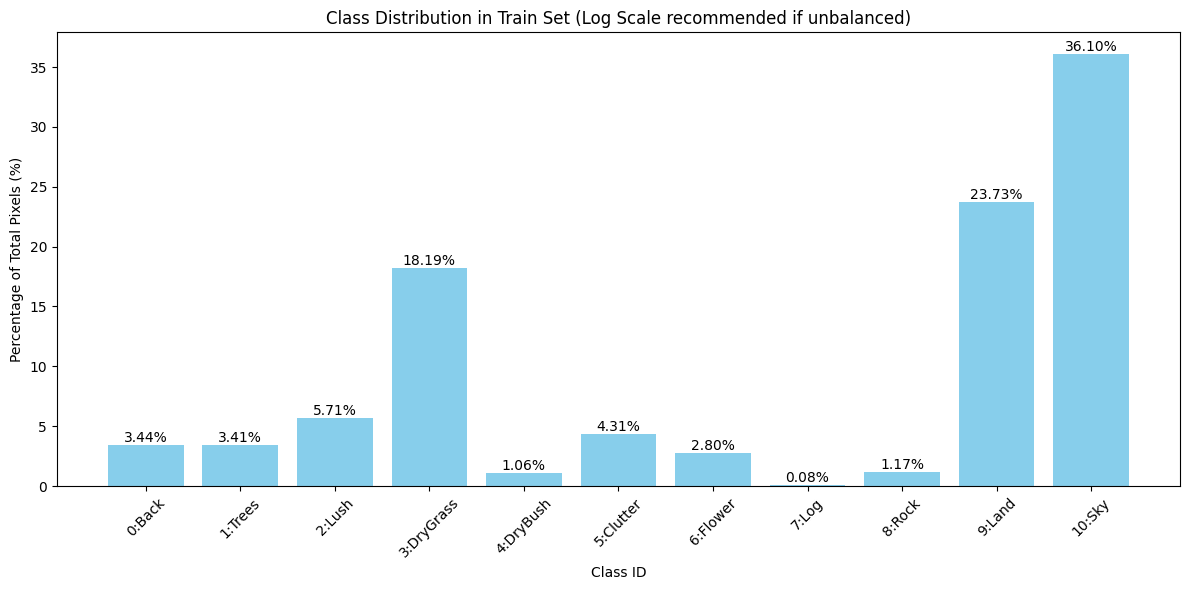


--- Analyzing Class Distribution for Test Set ---


Counting Pixels: 100%|████████████████████████| 126/126 [00:37<00:00,  3.39it/s]



Class Name      | Pixels       | Percentage
---------------------------------------------
0:Back          | 15715507     | 3.3200%
1:Trees         | 1239345      | 0.2618%
2:Lush          | 6554         | 0.0014%
3:DryGrass      | 81079720     | 17.1285%
4:DryBush       | 14411314     | 3.0445%
5:Clutter       | 0            | 0.0000%
6:Flower        | 0            | 0.0000%
7:Log           | 0            | 0.0000%
8:Rock          | 83811552     | 17.7056%
9:Land          | 198931232    | 42.0253%
10:Sky          | 78165640     | 16.5129%


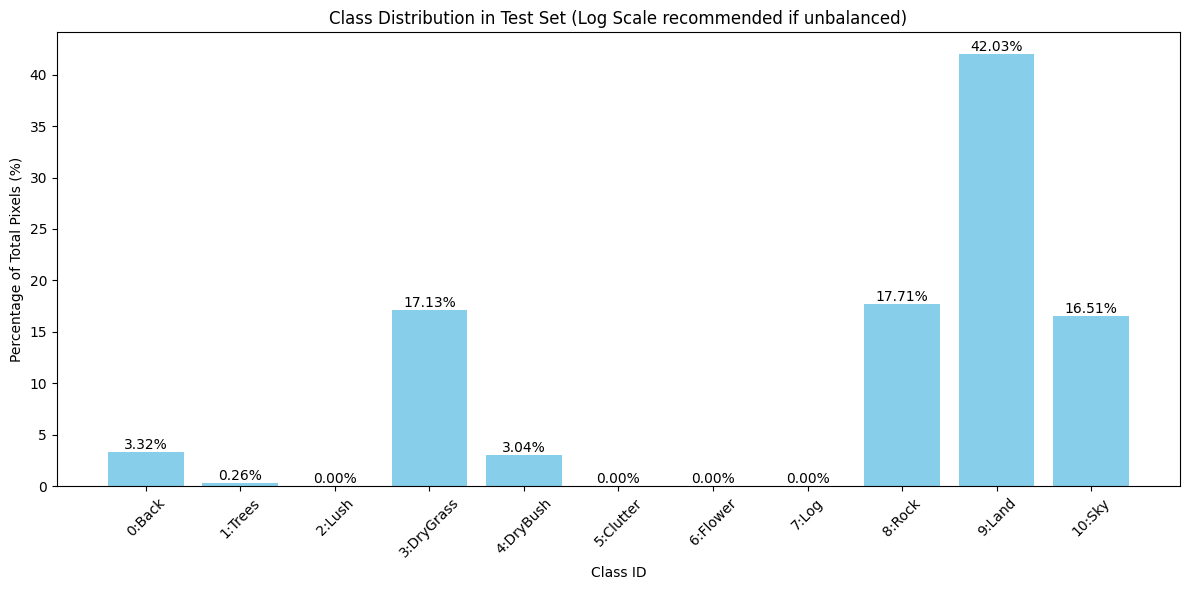

In [18]:
import matplotlib.pyplot as plt

def analyze_class_distribution(loader, num_classes=11, name="Dataset"):
    print(f"\n--- Analyzing Class Distribution for {name} ---")
    
    # Initialize counter
    class_counts = torch.zeros(num_classes).to(device)
    total_pixels = 0
    
    # Iterate (No gradients needed)
    with torch.no_grad():
        for _, masks in tqdm.tqdm(loader, desc="Counting Pixels"):
            masks = masks.to(device)
            
            # Flatten mask to 1D and count occurrences
            # bincount is fast on GPU
            counts = torch.bincount(masks.view(-1), minlength=num_classes)
            
            # Add to total
            class_counts += counts
            total_pixels += masks.numel()

    # Move to CPU for plotting
    class_counts = class_counts.cpu().numpy()
    percentages = (class_counts / total_pixels) * 100
    
    # --- Visualization ---
    class_names = [
        "0:Back", "1:Trees", "2:Lush", "3:DryGrass", "4:DryBush", 
        "5:Clutter", "6:Flower", "7:Log", "8:Rock", "9:Land", "10:Sky"
    ]
    
    # Print Table
    print(f"\n{'Class Name':<15} | {'Pixels':<12} | {'Percentage':<10}")
    print("-" * 45)
    for i in range(num_classes):
        print(f"{class_names[i]:<15} | {int(class_counts[i]):<12} | {percentages[i]:.4f}%")
        
    # Plot Bar Chart
    plt.figure(figsize=(12, 6))
    bars = plt.bar(class_names, percentages, color='skyblue')
    plt.title(f"Class Distribution in {name} (Log Scale recommended if unbalanced)")
    plt.ylabel("Percentage of Total Pixels (%)")
    plt.xlabel("Class ID")
    plt.xticks(rotation=45)
    
    # Add value labels
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}%', ha='center', va='bottom')
    
    plt.tight_layout()
    plt.show()

    return percentages

# Run on Train and Test
train_dist = analyze_class_distribution(train_loader, name="Train Set")
test_dist = analyze_class_distribution(test_loader, name="Test Set")

In [19]:
# import torch
# import gc
# import os

# # --- 1. MEMORY CLEANUP ---
# gc.collect()
# torch.cuda.empty_cache()
# os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"

# # --- 2. SAFE CONFIGURATION ---
# # We use Batch Size 4 to be safe. 
# # 4 * 4 = 16 effective batch size (same as before)
# BATCH_SIZE = 4       
# accumulation_steps = 4 

# # DINOv2 likes multiples of 14. 
# # 924 is the closest multiple of 14 to your 912 target (14 * 66 = 924)
# H = 518
# W = 924 

# EPOCHS = 20
# FREEZE_EPOCHS = 3  # Unfreeze earlier since Small model learns fast
# LR = 5e-4          # Lower learning rate slightly for Small model stability

# print(f"Memory Cleared. Config: BS={BATCH_SIZE}, Accum={accumulation_steps}, Res={H}x{W}")